<a href="https://colab.research.google.com/github/Mateus-VF-Araujo/AED2/blob/Work_Branch/LOTUS_testes.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

  # **L.O.T.U.S. - Linguística Oriental: Topologia de Usos Semântico**
---

 Pessoas que aprendem japonês ou chinês podem encontrar formas escritas iguais ou semelhantes que possuem significados diferentes entre as línguas, causando interpretações equivocadas. Diante disso, as formas escritas compartilhadas entre chinês e japonês apresentam diferenças estruturais em seus contextos lexicais que se relacionam com sua divergência semântica?

In [ ]:
# Utiliza dicionários provenientes de CC-CEDICT + JMdict

# Ideia:
#   Chinês:
#       palavra chinesa <-> caracteres chineses

#   Japonês:
#       palavra japonesa <-> kanjis/caracteres

#   Depois:
#       comparar as duas redes através dos caracteres
#       compartilhados entre os idiomas.

# Setup

In [ ]:
#Variáveis de correções
DEBUG_MODE = False
HTTPS_VERIFY = False

In [ ]:
# 1. Instalação das bibliotecas

!pip -q install networkx matplotlib pandas requests lxml pyvis


# 2. Instalação de uma fonte com suporte a chinês e japonês

!apt-get -qq update
!apt-get -qq install -y fonts-noto-cjk

# Limpa caches antigos
!rm -rf ~/.cache/matplotlib
!rm -rf ~/.cache/fontconfig

# Atualiza o cache do sistema de fontes
!fc-cache -f

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 756.0/756.0 kB 12.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 79.0 MB/s eta 0:00:00
W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Selecting previously unselected package fonts-noto-cjk.
(Reading database ... 122815 files and directories currently installed.)
Preparing to unpack .../fonts-noto-cjk_1%3a20230817+repack1-3_all.deb ...
Unpacking fonts-noto-cjk (1:20230817+repack1-3) ...
Setting up fonts-noto-cjk (1:20230817+repack1-3) ...
Processing triggers for fontconfig (2.15.0-1.1ubuntu2) ...


In [ ]:
# 3. Imports

import re
import gzip
import requests
import unicodedata

import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import xml.etree.ElementTree as ET    #pro XML do JM-EDICT

from matplotlib.font_manager import FontProperties
from collections import Counter

## Configuração das fontes

In [ ]:
# 4. Configuração da fonte CJK
## Para mais opções de fontes: https://en.wikipedia.org/wiki/List_of_CJK_fonts

import matplotlib.font_manager as fm
from matplotlib.font_manager import FontProperties

font_candidates = [
    f for f in fm.findSystemFonts()
    if "NotoSansCJK" in f or "NotoSerifCJK" in f
]

print("Fontes CJK encontradas:")
for f in font_candidates:
    print(" ", f)

if not font_candidates:
    raise RuntimeError("Nenhuma fonte CJK foi encontrada.")

font_path = font_candidates[0]

print("\nFonte selecionada:")
print(font_path)

cjk_font = FontProperties(fname=font_path)

print("\nNome interno da fonte:")
print(cjk_font.get_name())

# Seleciona uma fonte

font_path = font_candidates[0]

print("\nFonte selecionada:")
print(font_path)


# Cria FontProperties diretamente a partir do arquivo

cjk_font = FontProperties(fname=font_path)

print("\nNome interno da fonte:")
print(cjk_font.get_name())

# Teste imediato da fonte


if DEBUG_MODE:
  plt.figure(figsize=(10, 2))

  plt.text(
      0.05,
      0.65,
      "中文测试：你好世界",
      fontproperties=cjk_font,
      fontsize=20
  )

  plt.text(
      0.05,
      0.25,
      "日本語テスト：こんにちは世界",
      fontproperties=cjk_font,
      fontsize=20
  )

  plt.axis("off")
  plt.tight_layout()
  plt.show()

Fontes CJK encontradas:
  /usr/share/fonts/opentype/noto/NotoSerifCJK-Bold.ttc
  /usr/share/fonts/opentype/noto/NotoSansCJK-Regular.ttc
  /usr/share/fonts/opentype/noto/NotoSansCJK-Bold.ttc
  /usr/share/fonts/opentype/noto/NotoSerifCJK-Regular.ttc

Fonte selecionada:
/usr/share/fonts/opentype/noto/NotoSerifCJK-Bold.ttc

Nome interno da fonte:
Noto Serif CJK JP

Fonte selecionada:
/usr/share/fonts/opentype/noto/NotoSerifCJK-Bold.ttc

Nome interno da fonte:
Noto Serif CJK JP


In [ ]:
# 5. Função para identificar caracteres Han/Kanji

def is_han(char):
    """
    Verifica se o caractere pertence aos principais blocos
    Unicode utilizados pelos caracteres Han/Kanji.
    """

    code = ord(char)

    return (
        0x4E00 <= code <= 0x9FFF or   # CJK Unified Ideographs
        0x3400 <= code <= 0x4DBF or   # CJK Extension A
        0xF900 <= code <= 0xFAFF      # CJK Compatibility Ideographs
    )


def extract_han(text):
    """
    Retorna os caracteres Han presentes em uma palavra.
    """

    return [char for char in text if is_han(char)]

## Downloads dos bancos de dados

In [ ]:
# 6. Download do CC-CEDICT

cedict_url = (
    "https://www.mdbg.net/chinese/export/cedict/"
    "cedict_1_0_ts_utf-8_mdbg.txt.gz"
)

cedict_response = requests.get(cedict_url,verify=HTTPS_VERIFY)

if cedict_response.status_code != 200:
    raise RuntimeError(
        f"Erro ao baixar CC-CEDICT: "
        f"HTTP {cedict_response.status_code}"
    )

cedict_text = gzip.decompress(
    cedict_response.content
).decode("utf-8")

if DEBUG_MODE:
  print("CC-CEDICT baixado com sucesso.")
  print("Tamanho:", len(cedict_text), "caracteres")

# 7. Parsing simplificado do CC-CEDICT

cedict_pattern = re.compile(
    r"^(\S+)\s+(\S+)\s+\[(.*?)\]\s+/(.*)/$"
)

chinese_entries = []

for line in cedict_text.splitlines():

    # Ignora comentários
    if line.startswith("#"):
        continue

    match = cedict_pattern.match(line)

    if not match:
        continue

    traditional = match.group(1)
    simplified = match.group(2)
    pinyin = match.group(3)
    definition = match.group(4)

    chinese_entries.append({
        "traditional": traditional,
        "simplified": simplified,
        "pinyin": pinyin,
        "definition": definition
    })


df_cn = pd.DataFrame(chinese_entries)

print("\nEntradas do CC-CEDICT:")
print(df_cn.head())

print("\nTotal de entradas:")
print(len(df_cn))

# 8. Download do JMdict

jmdict_url = "https://ftp.edrdg.org/pub/Nihongo/JMdict_e.gz"

jmdict_response = requests.get(jmdict_url,verify=HTTPS_VERIFY)

if jmdict_response.status_code != 200:
    raise RuntimeError(
        f"Erro ao baixar JMdict: "
        f"HTTP {jmdict_response.status_code}"
    )

jmdict_text = gzip.decompress(
    jmdict_response.content
).decode("utf-8")

print("\nJMdict baixado com sucesso.")
print("Tamanho:", len(jmdict_text), "caracteres")


# 9. Parsing simplificado do JMdict

# O JMdict possui estrutura XML.

# - keb = palavra escrita com kanji
# - reb = leitura
# - gloss = significado



root = ET.fromstring(jmdict_text)

japanese_entries = []

for entry in root.findall("entry"):

    kebs = entry.findall("k_ele")
    rebs = entry.findall("r_ele")

    glosses = entry.findall(".//gloss")

    if len(kebs) == 0:
        continue

    word = kebs[0].findtext("keb")

    reading = ""

    if len(rebs) > 0:
        reading = rebs[0].findtext("reb")

    meanings = []

    for gloss in glosses:
        if gloss.text:
            meanings.append(gloss.text)

    definition = "; ".join(meanings)

    japanese_entries.append({
        "word": word,
        "reading": reading,
        "definition": definition
    })


df_jp = pd.DataFrame(japanese_entries)

print("\nEntradas do JMdict:")
print(df_jp.head())

print("\nTotal de entradas:")
print(len(df_jp))

/usr/local/lib/python3.13/dist-packages/urllib3/connectionpool.py:1097: InsecureRequestWarning: Unverified HTTPS request is being made to host 'www.mdbg.net'. Adding certificate verification is strongly advised. See: https://urllib3.readthedocs.io/en/latest/advanced-usage.html#tls-warnings
  warnings.warn(



Entradas do CC-CEDICT:
  traditional simplified                                            pinyin  \
0         110        110                                   yao1 yao1 ling2   
1         119        119                                    yao1 yao1 jiu3   
2         11區        11区                                            11 Qu1   
3         120        120                                    yao1 er4 ling2   
4   2019冠狀病毒病  2019冠状病毒病  er4 ling2 yi1 jiu3 guan1 zhuang4 bing4 du2 bing4   

                                          definition  
0  the emergency number for law enforcement in Ma...  
1  the emergency number for firefighting services...  
2  (ACG) Japan (from the anime "Code Geass", in w...  
3  the emergency number for medical assistance an...  
4  COVID-19, the coronavirus disease identified i...  

Total de entradas:
125297


/usr/local/lib/python3.13/dist-packages/urllib3/connectionpool.py:1097: InsecureRequestWarning: Unverified HTTPS request is being made to host 'ftp.edrdg.org'. Adding certificate verification is strongly advised. See: https://urllib3.readthedocs.io/en/latest/advanced-usage.html#tls-warnings
  warnings.warn(



JMdict baixado com sucesso.
Tamanho: 57741789 caracteres

Entradas do JMdict:
   word    reading                                         definition
0     〃        おなじ                                         ditto mark
1     仝         どう                                    "as above" mark
2     々         のま                              kanji repetition mark
3     ○         まる  circle; "correct"; "good"; *; _; period; full ...
4  ＡＢＣ順  エービーシーじゅん                                 alphabetical order

Total de entradas:
177652


# Criação de redes

In [ ]:
# Variáveis

# Para não criar uma rede gigantesca durante a demonstração, pode-se limitar os dados.
# Utilize (-1) para copiar utilizar o dataframe completo
N_CN = 1000
N_JP = 1000


Tamanho utilizado:
Chinês: 1000
Japonês: 1000

REDE CHINESA
Nós: 1843
Arestas: 2676

REDE JAPONESA
Nós: 1677
Arestas: 1461

CARACTERES COMPARTILHADOS
Caracteres chineses: 915
Caracteres japoneses: 762
Caracteres compartilhados: 206

Primeiros caracteres compartilhados:
['一', '丁', '丈', '三', '上', '下', '世', '中', '主', '久', '事', '些', '交', '人', '他', '付', '以', '休', '会', '位', '体', '何', '倒', '先', '光', '入', '共', '内', '凸', '出', '分', '切', '列', '利', '刻', '前', '力', '化', '半', '南', '印', '原', '参', '又', '双', '反', '取', '口', '古', '可']

Comparação de graus:


,caractere,grau_chines,grau_japones
0,一,655,1
178,而,20,1
79,字,17,3
189,言,17,14
38,半,16,1
78,子,15,11
75,如,12,3
3,三,12,2
90,年,12,1
191,路,10,1



Nós da rede de exemplo: 1155
Arestas da rede de exemplo: 1663


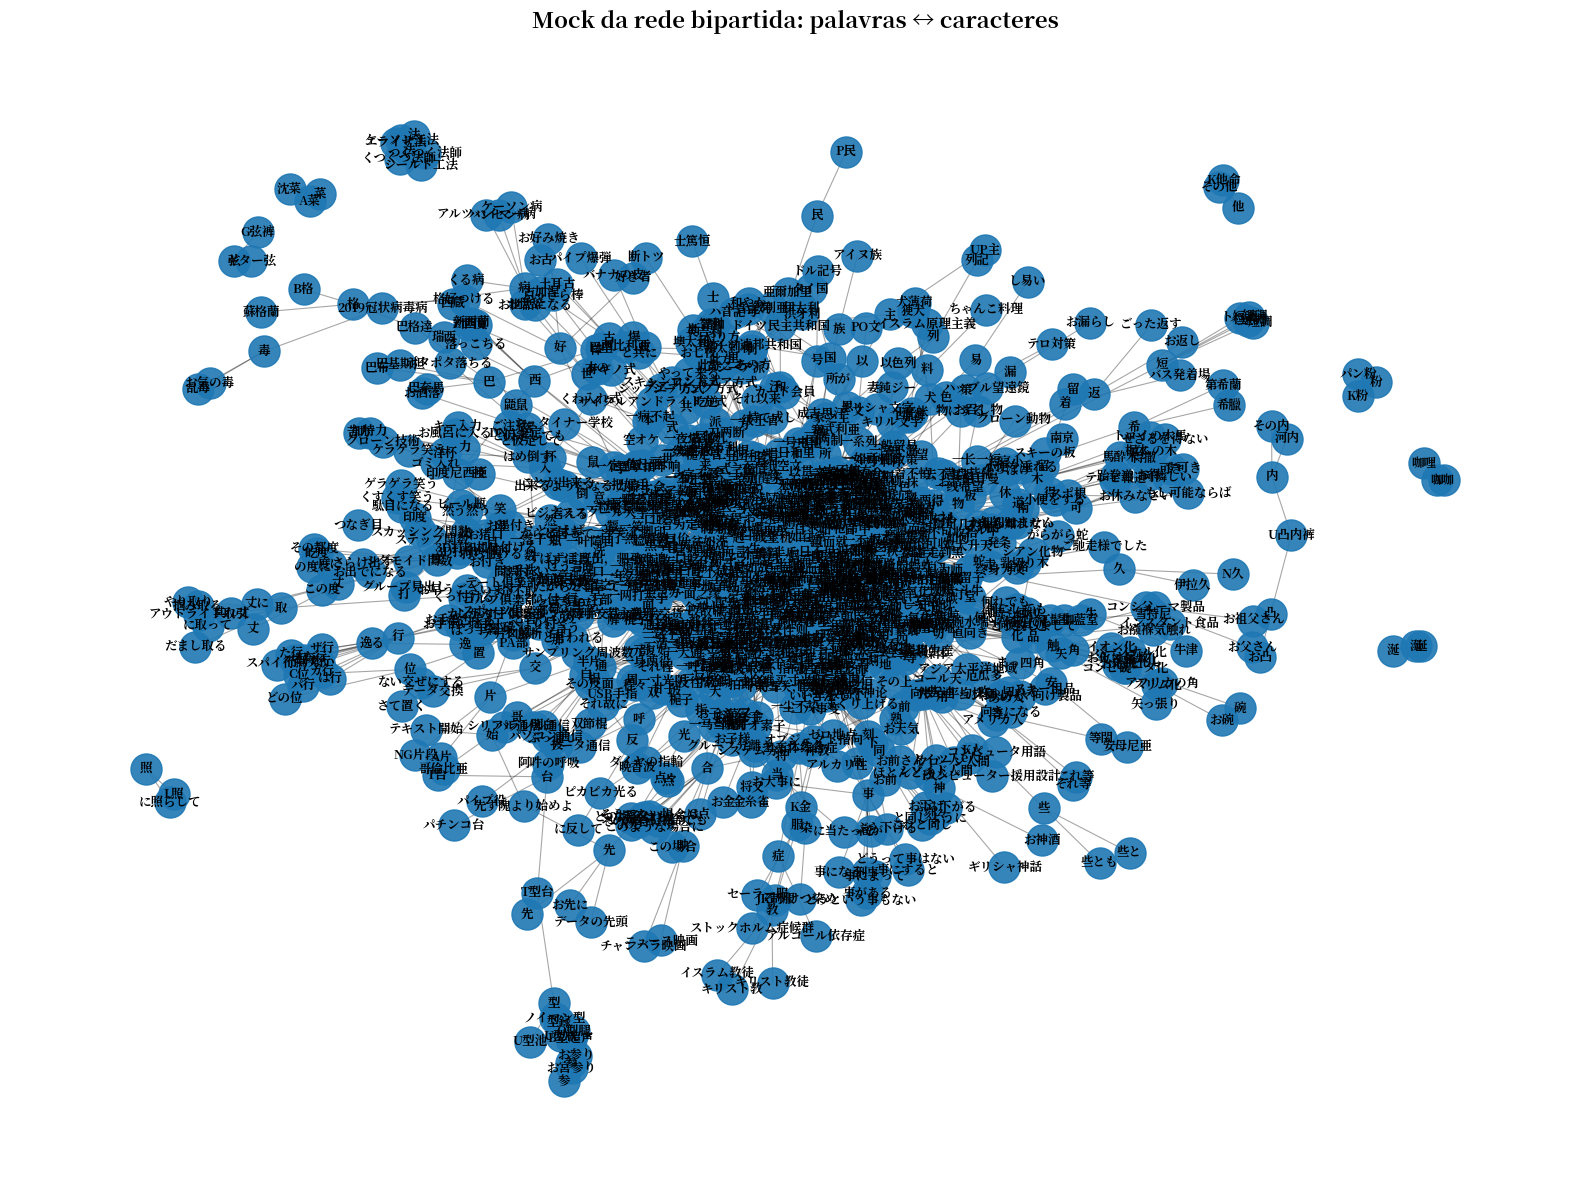


REDE CONJUNTA
Nós: 3314
Arestas: 4137

EXEMPLO DE CARACTERE COMPARTILHADO
Caractere: 一

Palavras chinesas:
  一
  一一
  一一对应
  一一映射
  一丁不识
  一丁点
  一下
  一下儿
  一下子
  一不做，二不休

Palavras japonesas:
  ちょっと一杯


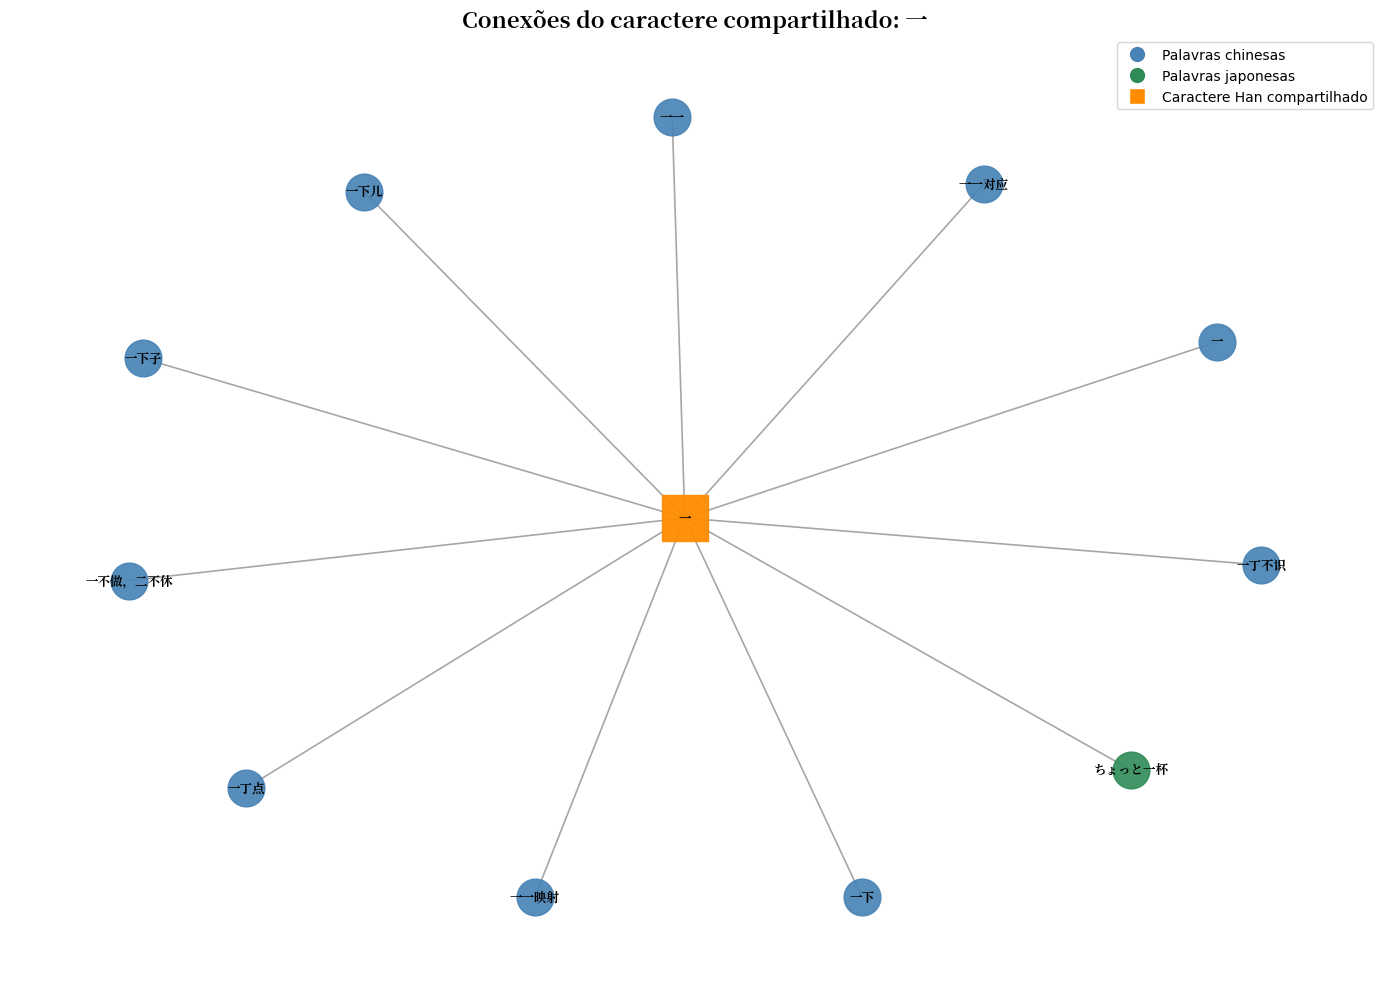


CONEXÃO ENTRE OS IDIOMAS

Caractere compartilhado selecionado:
一

Palavras chinesas ligadas:
  一
  一一
  一一对应
  一一映射
  一丁不识
  一丁点
  一下
  一下儿
  一下子
  一不做，二不休
  一不小心
  一世
  一丘之貉
  一丢丢
  一并
  一中一台
  一中原则
  一之为甚
  一之谓甚
  一干二净

Palavras japonesas ligadas:
  ちょっと一杯

MATRIZ DE INCIDÊNCIA — CHINÊS


,palavra,三,体,冠,制,区,印,合,后,店,打,机,毒,状,病,症,综,胶
0,11区,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0
1,2019冠状病毒病,0,0,1,0,0,0,0,0,0,0,0,1,1,1,0,0,0
2,21三体综合症,1,1,0,0,0,0,1,0,0,0,0,0,0,0,1,1,0
3,3D打印,0,0,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0
4,3D打印机,0,0,0,0,0,1,0,0,0,1,1,0,0,0,0,0,0
5,4S店,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0
6,502胶,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1
7,95后,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0
8,AA制,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0
9,AB制,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0



MATRIZ DE INCIDÊNCIA — JAPONÊS


,palavra,仝,吸,吽,呼,悪,明,木,白,論,遇,酔,阿,響,順,馬
0,仝,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0
1,ＡＢＣ順,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0
2,Ｎ響,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0
3,阿吽の呼吸,0,1,1,1,0,0,0,0,0,0,0,1,0,0,0
4,明白,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0
5,明かん,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0
6,悪どい,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0
7,論う,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0
8,遇う,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0
9,馬酔木,0,0,0,0,0,0,1,0,0,0,1,0,0,0,1




RESUMO
Entradas chinesas analisadas: 1000
Entradas japonesas analisadas: 1000
Caracteres chineses: 915
Caracteres japoneses: 762
Caracteres compartilhados: 206
Nós da rede chinesa: 1843
Arestas da rede chinesa: 2676
Nós da rede japonesa: 1677
Arestas da rede japonesa: 1461
Nós da rede conjunta: 3314
Arestas da rede conjunta: 4137


In [ ]:
# 10. Limitação dos datasets
# N_CN/N_JP = -1 significa utilizar o dataframe completo.
df_cn_mock = df_cn.copy() if N_CN == -1 else df_cn.head(N_CN).copy()
df_jp_mock = df_jp.copy() if N_JP == -1 else df_jp.head(N_JP).copy()

print("\nTamanho utilizado:")
print("Chinês:", len(df_cn_mock))
print("Japonês:", len(df_jp_mock))


def build_chinese_graph(df, column, word_prefix, language):
    """Cria uma rede bipartida de palavras chinesas e caracteres Han."""
    graph = nx.Graph()
    for _, row in df.iterrows():
        value = row.get(column, "")
        if pd.isna(value):
            continue
        word = str(value).strip()
        if not word:
            continue
        word_node = f"{word_prefix}{word}"
        chars = set(extract_han(word))
        if not chars:
            continue
        graph.add_node(word_node, bipartite="word", language=language, label=word)
        for char in chars:
            char_node = f"CHAR:{char}"
            graph.add_node(char_node, bipartite="character", language="shared", label=char)
            graph.add_edge(word_node, char_node, relation="contains_character")
    return graph


def build_japanese_graph(df):
    """Cria uma rede bipartida de palavras japonesas e caracteres Han/Kanji."""
    graph = nx.Graph()
    for _, row in df.iterrows():
        value = row.get("word", "")
        if pd.isna(value):
            continue
        word = str(value).strip()
        chars = set(extract_han(word))
        if not word or not chars:
            continue
        word_node = f"JP_WORD:{word}"
        graph.add_node(word_node, bipartite="word", language="japanese", label=word)
        for char in chars:
            char_node = f"CHAR:{char}"
            graph.add_node(char_node, bipartite="character", language="shared", label=char)
            graph.add_edge(word_node, char_node, relation="contains_character")
    return graph


# Redes chinesas separadas: cada uma usa apenas uma coluna do CC-CEDICT.
# G_cn mantém o nome antigo para que as células seguintes continuem funcionando.
G_cn_trad = build_chinese_graph(
    df_cn_mock, "traditional", "CN_TRAD_WORD:", "chinese_traditional"
)
G_cn_simp = build_chinese_graph(
    df_cn_mock, "simplified", "CN_WORD:", "chinese_simplified"
)
G_cn = G_cn_simp  # compatibilidade com as análises existentes
G_jp = build_japanese_graph(df_jp_mock)

# Grafos de comparação: compartilham os nós CHAR: quando a forma gráfica coincide.
G_jp_vs_trad = nx.compose(G_jp, G_cn_trad)
G_jp_vs_simp = nx.compose(G_jp, G_cn_simp)

# Terceira comparação: duas formas chinesas ligadas quando vêm da mesma entrada
# do CC-CEDICT. Os nós de palavra são separados para preservar a variante.
G_cn_simp_vs_trad = nx.compose(G_cn_simp, G_cn_trad)
for _, row in df_cn_mock.iterrows():
    simp_value = row.get("simplified", "")
    trad_value = row.get("traditional", "")
    if pd.isna(simp_value) or pd.isna(trad_value):
        continue
    simplified = str(simp_value).strip()
    traditional = str(trad_value).strip()
    if not simplified or not traditional:
        continue
    simp_node = f"CN_SIMP_PAIR:{simplified}"
    trad_node = f"CN_TRAD_WORD:{traditional}"
    # Nó auxiliar separado evita misturar as palavras simplificadas da rede legado.
    G_cn_simp_vs_trad.add_node(
        simp_node, bipartite="word", language="chinese_simplified", label=simplified
    )
    for char in set(extract_han(simplified)):
        char_node = f"CHAR:{char}"
        G_cn_simp_vs_trad.add_node(
            char_node, bipartite="character", language="shared", label=char
        )
        G_cn_simp_vs_trad.add_edge(simp_node, char_node, relation="contains_character")
    if trad_node in G_cn_simp_vs_trad:
        G_cn_simp_vs_trad.add_edge(
            simp_node, trad_node, relation="traditional_simplified_entry_pair"
        )

# 13. Estatísticas básicas das redes

print("\n==============================")
print("REDE CHINESA")
print("==============================")

print("Nós:", G_cn.number_of_nodes())
print("Arestas:", G_cn.number_of_edges())


print("\n==============================")
print("REDE JAPONESA")
print("==============================")

print("Nós:", G_jp.number_of_nodes())
print("Arestas:", G_jp.number_of_edges())

# 14. Caracteres compartilhados

chars_cn = {
    node
    for node, data in G_cn.nodes(data=True)
    if data.get("bipartite") == "character"
}

chars_jp = {
    node
    for node, data in G_jp.nodes(data=True)
    if data.get("bipartite") == "character"
}

shared_chars = chars_cn.intersection(chars_jp)

print("\n==============================")
print("CARACTERES COMPARTILHADOS")
print("==============================")

print("Caracteres chineses:", len(chars_cn))
print("Caracteres japoneses:", len(chars_jp))
print("Caracteres compartilhados:", len(shared_chars))


# 15. Exemplos de caracteres compartilhados

shared_labels = sorted([
    node.replace("CHAR:", "")
    for node in shared_chars
])

print("\nPrimeiros caracteres compartilhados:")

print(shared_labels[:50])


# 16. Grau dos caracteres

# O grau de um caractere representa quantas palavras estão
# ligadas a ele dentro da rede.


degree_cn = {
    node.replace("CHAR:", ""): G_cn.degree(node)
    for node in chars_cn
}

degree_jp = {
    node.replace("CHAR:", ""): G_jp.degree(node)
    for node in chars_jp
}



# 17. Comparação de grau para caracteres compartilhados

degree_comparison = []

for char in shared_labels:

    degree_comparison.append({
        "caractere": char,
        "grau_chines": degree_cn.get(char, 0),
        "grau_japones": degree_jp.get(char, 0)
    })

df_degree = pd.DataFrame(degree_comparison)

df_degree = df_degree.sort_values(
    by="grau_chines",
    ascending=False
)

print("\nComparação de graus:")
display(df_degree.head(20))


# 18. Exemplo de rede bipartida

# Para a visualização, serão selecionados alguns caracteres
# compartilhados e algumas palavras associadas a eles.


EXAMPLE_CHARS = len(shared_labels)
WORDS_PER_CHAR = 100

example_chars = shared_labels[:EXAMPLE_CHARS]

example_nodes = set()

for char in example_chars:

    char_node = "CHAR:" + char

    example_nodes.add(char_node)

    # Vizinhos no grafo chinês
    neighbors_cn = list(G_cn.neighbors(char_node))

    for neighbor in neighbors_cn[:WORDS_PER_CHAR]:
        example_nodes.add(neighbor)

    # Vizinhos no grafo japonês
    neighbors_jp = list(G_jp.neighbors(char_node))

    for neighbor in neighbors_jp[:WORDS_PER_CHAR]:
        example_nodes.add(neighbor)


# Cria um novo grafo apenas para visualização
G_example = nx.Graph()

for node in example_nodes:

    if node in G_cn:
        data = G_cn.nodes[node]
        G_example.add_node(node, **data)

    elif node in G_jp:
        data = G_jp.nodes[node]
        G_example.add_node(node, **data)


# Adiciona arestas do chinês
for u, v in G_cn.edges():

    if u in example_nodes and v in example_nodes:
        G_example.add_edge(u, v)


# Adiciona arestas do japonês
for u, v in G_jp.edges():

    if u in example_nodes and v in example_nodes:
        G_example.add_edge(u, v)


print("\nNós da rede de exemplo:", G_example.number_of_nodes())
print("Arestas da rede de exemplo:", G_example.number_of_edges())


# ============================================================
# 19. Visualização da rede
# ============================================================

# Define a posição dos nós.
# O mesmo layout será utilizado para desenhar nós, arestas e rótulos.
pos = nx.spring_layout(
    G_example,
    seed=42
)

plt.figure(figsize=(16, 12))

# Desenha as arestas
nx.draw_networkx_edges(
    G_example,
    pos,
    alpha=0.35,
    width=0.8
)

# Desenha os nós
nx.draw_networkx_nodes(
    G_example,
    pos,
    node_size=500,
    alpha=0.9
)

# Desenha os rótulos manualmente.
# Isso permite passar diretamente o objeto FontProperties,
# evitando que o Matplotlib tente localizar a fonte pelo nome.
for node, (x, y) in pos.items():

    if node.startswith("CHAR:"):
        label = node.replace("CHAR:", "")

    elif node.startswith("CN_WORD:"):
        label = node.replace("CN_WORD:", "")

    elif node.startswith("JP_WORD:"):
        label = node.replace("JP_WORD:", "")

    else:
        label = node

    plt.text(
        x,
        y,
        label,
        fontproperties=cjk_font,
        fontsize=9,
        ha="center",
        va="center"
    )

plt.title(
    "Mock da rede bipartida: palavras ↔ caracteres",
    fontproperties=cjk_font,
    fontsize=16
)

plt.axis("off")
plt.tight_layout()
plt.show()


# ============================================================
# 20. Construção da rede conjunta
# ============================================================
#
# A rede conjunta reúne as redes chinesa e japonesa.
#
# Identificação dos nós:
#
#   CN_WORD: -> palavra chinesa
#   JP_WORD: -> palavra japonesa
#   CHAR:    -> caractere Han
#
# Como os caracteres possuem o mesmo identificador nos dois
# grafos, um caractere compartilhado torna-se um único nó na
# rede conjunta, conectando os dois idiomas.
# ============================================================

G_combined = nx.Graph()

# Adiciona a rede chinesa
G_combined.add_nodes_from(G_cn.nodes(data=True))
G_combined.add_edges_from(G_cn.edges())

# Adiciona a rede japonesa
G_combined.add_nodes_from(G_jp.nodes(data=True))
G_combined.add_edges_from(G_jp.edges())


print("\n==============================")
print("REDE CONJUNTA")
print("==============================")

print("Nós:", G_combined.number_of_nodes())
print("Arestas:", G_combined.number_of_edges())

# 21. Visualização de um caractere compartilhado

# A rede completa possui milhares de nós, portanto não é
# conveniente aplicar spring_layout() sobre todo o grafo.

# Em vez disso, é selecionado um caractere compartilhado e
# visualizadas algumas palavras chinesas e japonesas ligadas
# a ele.

# Cores:

#   Azul   -> palavras chinesas
#   Verde  -> palavras japonesas
#   Laranja -> caractere Han compartilhado

if len(shared_labels) > 0:

    # Seleciona um caractere compartilhado
    example_char = shared_labels[0]

    char_node = "CHAR:" + example_char

    # Seleciona palavras chinesas ligadas ao caractere


    cn_neighbors = [
        node
        for node in G_cn.neighbors(char_node)
        if node.startswith("CN_WORD:")
    ]

    # Seleciona palavras japonesas ligadas ao caractere

    jp_neighbors = [
        node
        for node in G_jp.neighbors(char_node)
        if node.startswith("JP_WORD:")
    ]

    # Limita a quantidade de palavras para manter a figura legível.
    cn_neighbors = cn_neighbors[:10]
    jp_neighbors = jp_neighbors[:10]

    # Cria um pequeno subgrafo apenas com esses nós

    nodes_example = (
        cn_neighbors
        + [char_node]
        + jp_neighbors
    )

    G_shared_example = G_combined.subgraph(
        nodes_example
    ).copy()

    print("\n==============================")
    print("EXEMPLO DE CARACTERE COMPARTILHADO")
    print("==============================")

    print("Caractere:", example_char)

    print("\nPalavras chinesas:")
    for node in cn_neighbors:
        print(" ", node.replace("CN_WORD:", ""))

    print("\nPalavras japonesas:")
    for node in jp_neighbors:
        print(" ", node.replace("JP_WORD:", ""))

    # Layout do pequeno subgrafo

    pos_shared = nx.spring_layout(
        G_shared_example,
        seed=42
    )

    # Figura

    plt.figure(figsize=(14, 10))

    # Desenha as arestas
    nx.draw_networkx_edges(
        G_shared_example,
        pos_shared,
        alpha=0.35,
        width=1.2
    )

    # Identifica os tipos de nó

    cn_nodes = [
        node
        for node in G_shared_example.nodes()
        if node.startswith("CN_WORD:")
    ]

    jp_nodes = [
        node
        for node in G_shared_example.nodes()
        if node.startswith("JP_WORD:")
    ]

    char_nodes = [
        node
        for node in G_shared_example.nodes()
        if node.startswith("CHAR:")
    ]

    # Nós das palavras chinesas

    nx.draw_networkx_nodes(
        G_shared_example,
        pos_shared,
        nodelist=cn_nodes,
        node_size=700,
        node_color="steelblue",
        alpha=0.9
    )

    # Nós das palavras japonesas

    nx.draw_networkx_nodes(
        G_shared_example,
        pos_shared,
        nodelist=jp_nodes,
        node_size=700,
        node_color="seagreen",
        alpha=0.9
    )

    # Nó do caractere compartilhado

    nx.draw_networkx_nodes(
        G_shared_example,
        pos_shared,
        nodelist=char_nodes,
        node_size=1100,
        node_shape="s",
        node_color="darkorange",
        alpha=0.95
    )

    # Rótulos

    # plt.text() é utilizado diretamente para garantir que a fonte CJK selecionada seja aplicada corretamente.

    for node, (x, y) in pos_shared.items():

        if node.startswith("CHAR:"):
            label = node.replace("CHAR:", "")

        elif node.startswith("CN_WORD:"):
            label = node.replace("CN_WORD:", "")

        elif node.startswith("JP_WORD:"):
            label = node.replace("JP_WORD:", "")

        else:
            label = node

        plt.text(
            x,
            y,
            label,
            fontproperties=cjk_font,
            fontsize=9,
            ha="center",
            va="center"
        )

    # Legenda

    from matplotlib.lines import Line2D

    legend_elements = [
        Line2D(
            [0],
            [0],
            marker="o",
            color="w",
            label="Palavras chinesas",
            markerfacecolor="steelblue",
            markersize=12
        ),

        Line2D(
            [0],
            [0],
            marker="o",
            color="w",
            label="Palavras japonesas",
            markerfacecolor="seagreen",
            markersize=12
        ),

        Line2D(
            [0],
            [0],
            marker="s",
            color="w",
            label="Caractere Han compartilhado",
            markerfacecolor="darkorange",
            markersize=12
        )
    ]

    plt.legend(
        handles=legend_elements,
        loc="best"
    )

    plt.title(
        f"Conexões do caractere compartilhado: {example_char}",
        fontproperties=cjk_font,
        fontsize=16
    )

    plt.axis("off")
    plt.tight_layout()
    plt.show()


# 22. Exemplo de conexão entre os idiomas

if len(shared_labels) > 0:

    example_char = shared_labels[0]

    char_node = "CHAR:" + example_char

    print("\n==============================")
    print("CONEXÃO ENTRE OS IDIOMAS")
    print("==============================")

    print("\nCaractere compartilhado selecionado:")
    print(example_char)

    print("\nPalavras chinesas ligadas:")

    if char_node in G_cn:

        for neighbor in list(
            G_cn.neighbors(char_node)
        )[:20]:

            print(
                " ",
                neighbor.replace("CN_WORD:", "")
            )

    print("\nPalavras japonesas ligadas:")

    if char_node in G_jp:

        for neighbor in list(
            G_jp.neighbors(char_node)
        )[:20]:

            print(
                " ",
                neighbor.replace("JP_WORD:", "")
            )


# 23. Matriz de incidência — exemplo chinês

# Seleciona algumas palavras chinesas
sample_cn_words = [
    node
    for node in G_cn.nodes()
    if node.startswith("CN_WORD:")
][:10]

# Seleciona os caracteres envolvidos nessas palavras
sample_chars = set()

for word_node in sample_cn_words:

    for neighbor in G_cn.neighbors(word_node):

        if neighbor.startswith("CHAR:"):

            sample_chars.add(
                neighbor.replace("CHAR:", "")
            )

sample_chars = sorted(sample_chars)


# Cria a matriz de incidência

incidence_cn = []

for word_node in sample_cn_words:

    word = word_node.replace(
        "CN_WORD:",
        ""
    )

    row = {
        "palavra": word
    }

    for char in sample_chars:

        char_node = "CHAR:" + char

        row[char] = int(
            G_cn.has_edge(
                word_node,
                char_node
            )
        )

    incidence_cn.append(row)


df_incidence_cn = pd.DataFrame(
    incidence_cn
)

print("\n==============================")
print("MATRIZ DE INCIDÊNCIA — CHINÊS")
print("==============================")

display(df_incidence_cn)


# 24. Matriz de incidência — exemplo japonês

# Seleciona algumas palavras japonesas
sample_jp_words = [
    node
    for node in G_jp.nodes()
    if node.startswith("JP_WORD:")
][:10]

# Seleciona os caracteres envolvidos nessas palavras
sample_chars_jp = set()

for word_node in sample_jp_words:

    for neighbor in G_jp.neighbors(word_node):

        if neighbor.startswith("CHAR:"):

            sample_chars_jp.add(
                neighbor.replace("CHAR:", "")
            )

sample_chars_jp = sorted(
    sample_chars_jp
)


# Cria a matriz de incidência

incidence_jp = []

for word_node in sample_jp_words:

    word = word_node.replace(
        "JP_WORD:",
        ""
    )

    row = {
        "palavra": word
    }

    for char in sample_chars_jp:

        char_node = "CHAR:" + char

        row[char] = int(
            G_jp.has_edge(
                word_node,
                char_node
            )
        )

    incidence_jp.append(row)


df_incidence_jp = pd.DataFrame(
    incidence_jp
)

print("\n==============================")
print("MATRIZ DE INCIDÊNCIA — JAPONÊS")
print("==============================")

display(df_incidence_jp)


# 25. Resumo final

print("\n")
print("=" * 60)
print("RESUMO")
print("=" * 60)

print(
    f"Entradas chinesas analisadas: "
    f"{len(df_cn_mock)}"
)

print(
    f"Entradas japonesas analisadas: "
    f"{len(df_jp_mock)}"
)

print(
    f"Caracteres chineses: "
    f"{len(chars_cn)}"
)

print(
    f"Caracteres japoneses: "
    f"{len(chars_jp)}"
)

print(
    f"Caracteres compartilhados: "
    f"{len(shared_chars)}"
)

print(
    f"Nós da rede chinesa: "
    f"{G_cn.number_of_nodes()}"
)

print(
    f"Arestas da rede chinesa: "
    f"{G_cn.number_of_edges()}"
)

print(
    f"Nós da rede japonesa: "
    f"{G_jp.number_of_nodes()}"
)

print(
    f"Arestas da rede japonesa: "
    f"{G_jp.number_of_edges()}"
)

print(
    f"Nós da rede conjunta: "
    f"{G_combined.number_of_nodes()}"
)

print(
    f"Arestas da rede conjunta: "
    f"{G_combined.number_of_edges()}"
)

## Comparações entre as três variantes

A última célula gera três visualizações identificadas:

- `G_jp_vs_trad`: japonês (JMdict) × chinês tradicional (CC-CEDICT), com caracteres compartilhados no centro.
- `G_jp_vs_simp`: japonês (JMdict) × chinês simplificado (CC-CEDICT), com caracteres compartilhados no centro.
- A comparação chinês simplificado × tradicional mostra **pares de formas diferentes da mesma entrada do CC-CEDICT** em duas colunas alinhadas.

Os desenhos são amostras legíveis das redes, não o grafo inteiro. As redes completas permanecem nas variáveis `G_jp`, `G_cn_trad`, `G_cn_simp` e nos grafos de comparação.

Resumo das redes completas carregadas:
  Caracteres no japonês: 762
  Caracteres no chinês tradicional: 940
  Caracteres no chinês simplificado: 915
  Compartilhados japonês/tradicional: 243
  Compartilhados japonês/simplificado: 206


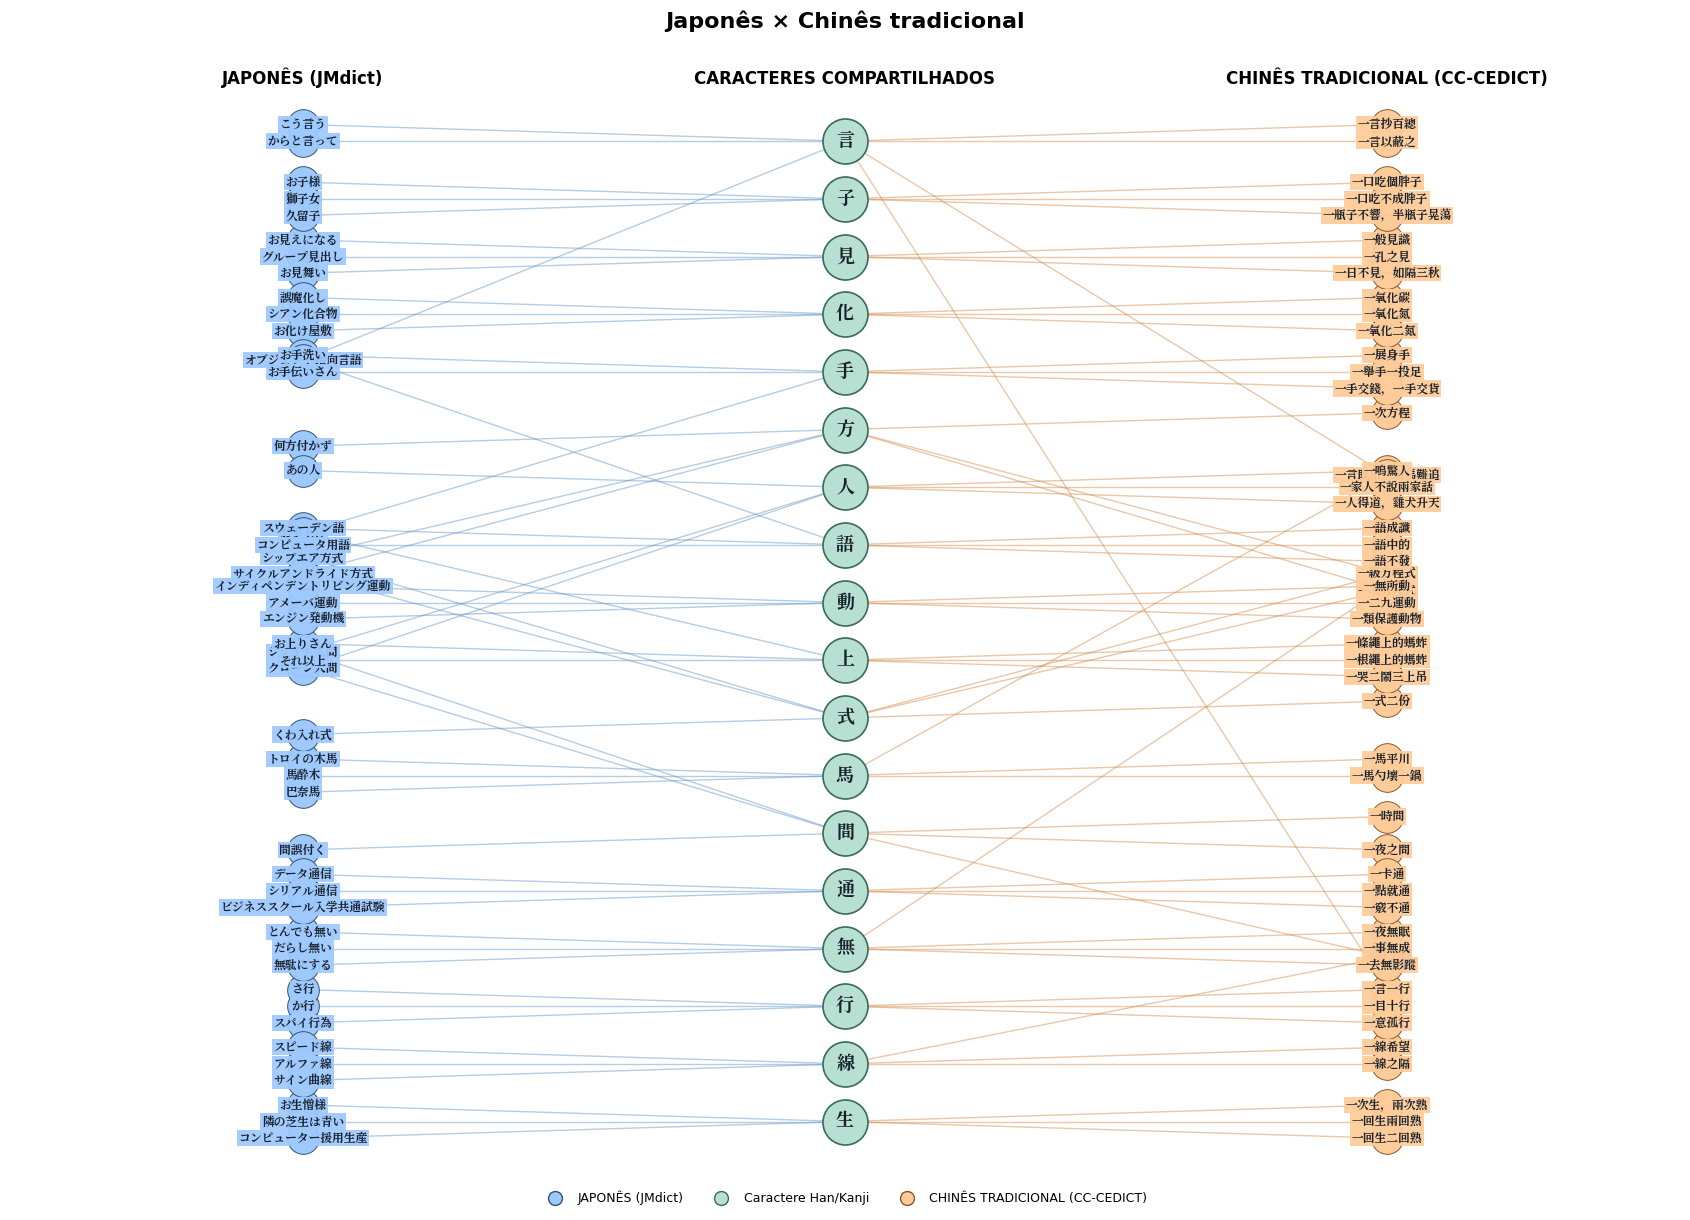

Japonês × Chinês tradicional: 18 caracteres compartilhados; 48 palavras à esquerda; 50 palavras à direita; 110 ligações na amostra visual.


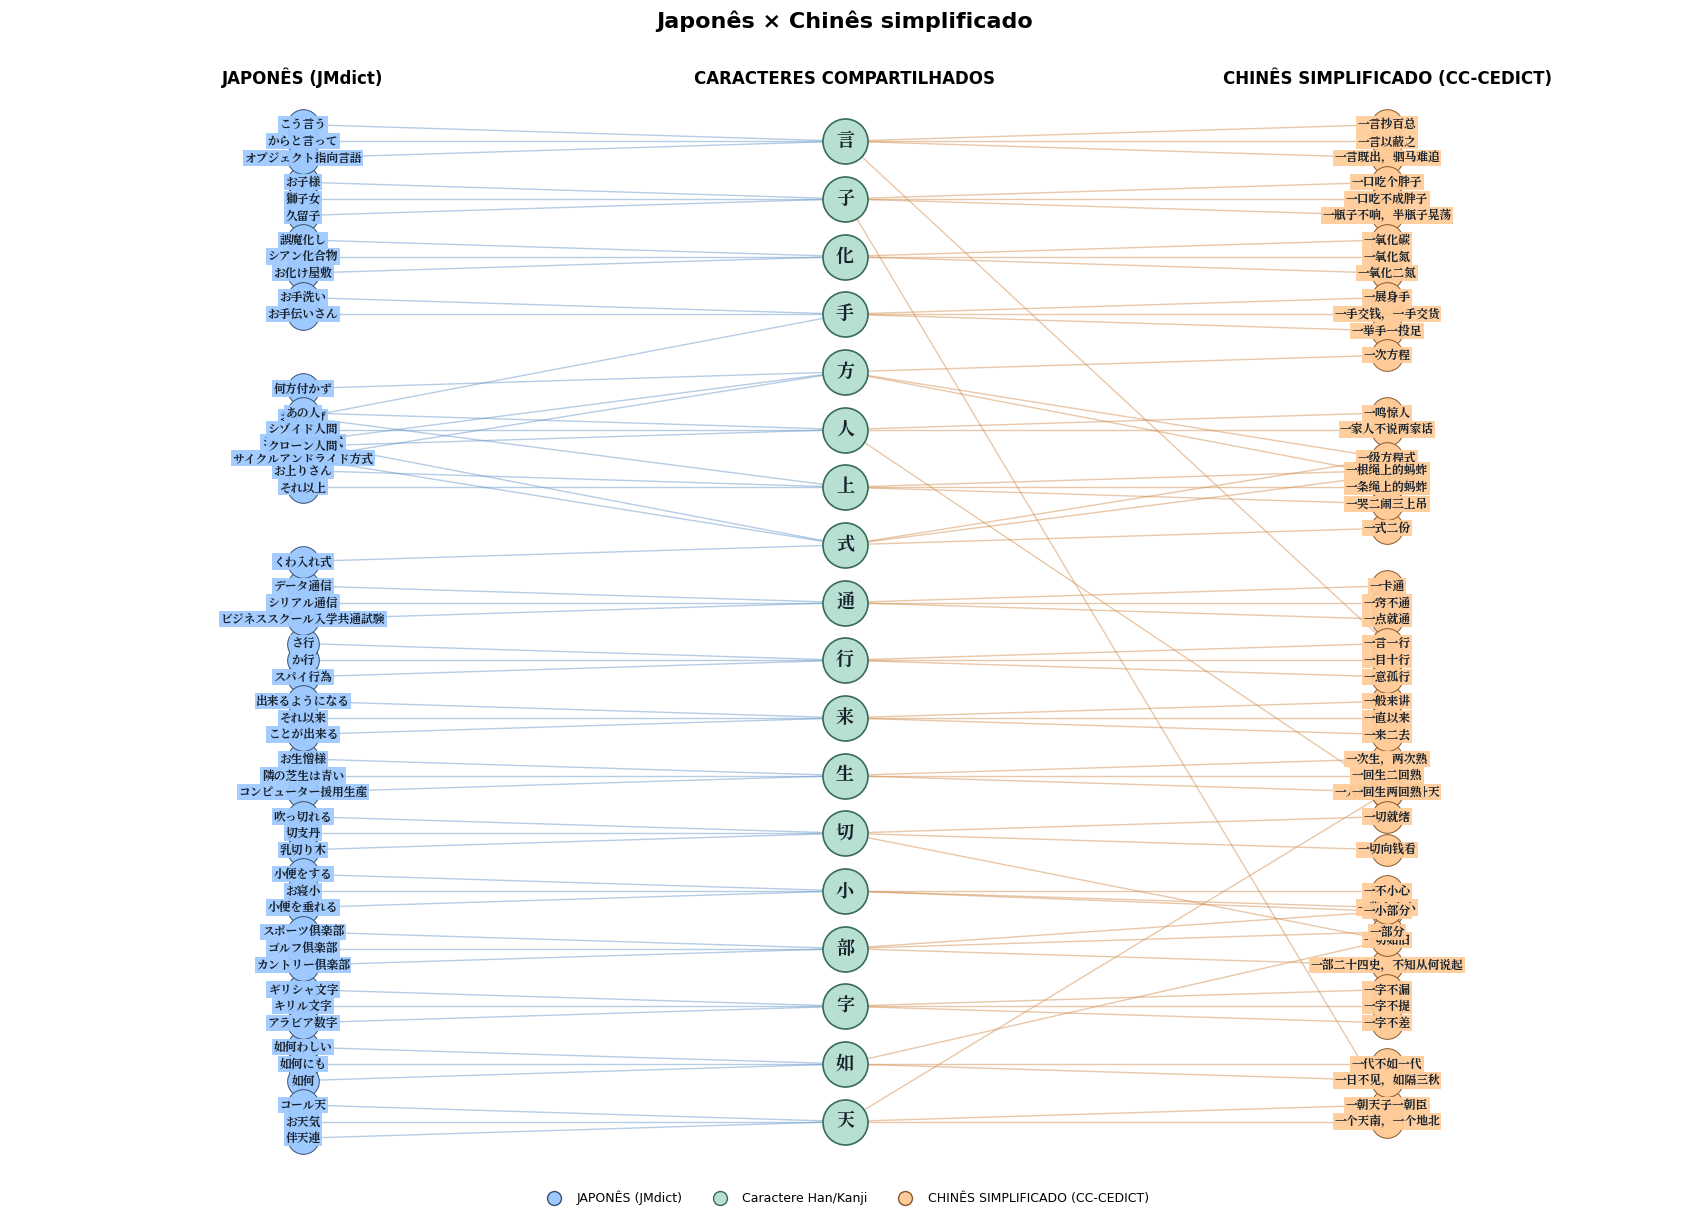

Japonês × Chinês simplificado: 18 caracteres compartilhados; 51 palavras à esquerda; 49 palavras à direita; 110 ligações na amostra visual.


/tmp/ipykernel_978/1880503734.py:226: UserWarning: Glyph 174220 (\N{CJK UNIFIED IDEOGRAPH-2A88C}) missing from font(s) Noto Serif CJK JP.
  fig.tight_layout()
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 174220 (\N{CJK UNIFIED IDEOGRAPH-2A88C}) missing from font(s) Noto Serif CJK JP.
  fig.canvas.print_figure(bytes_io, **kw)


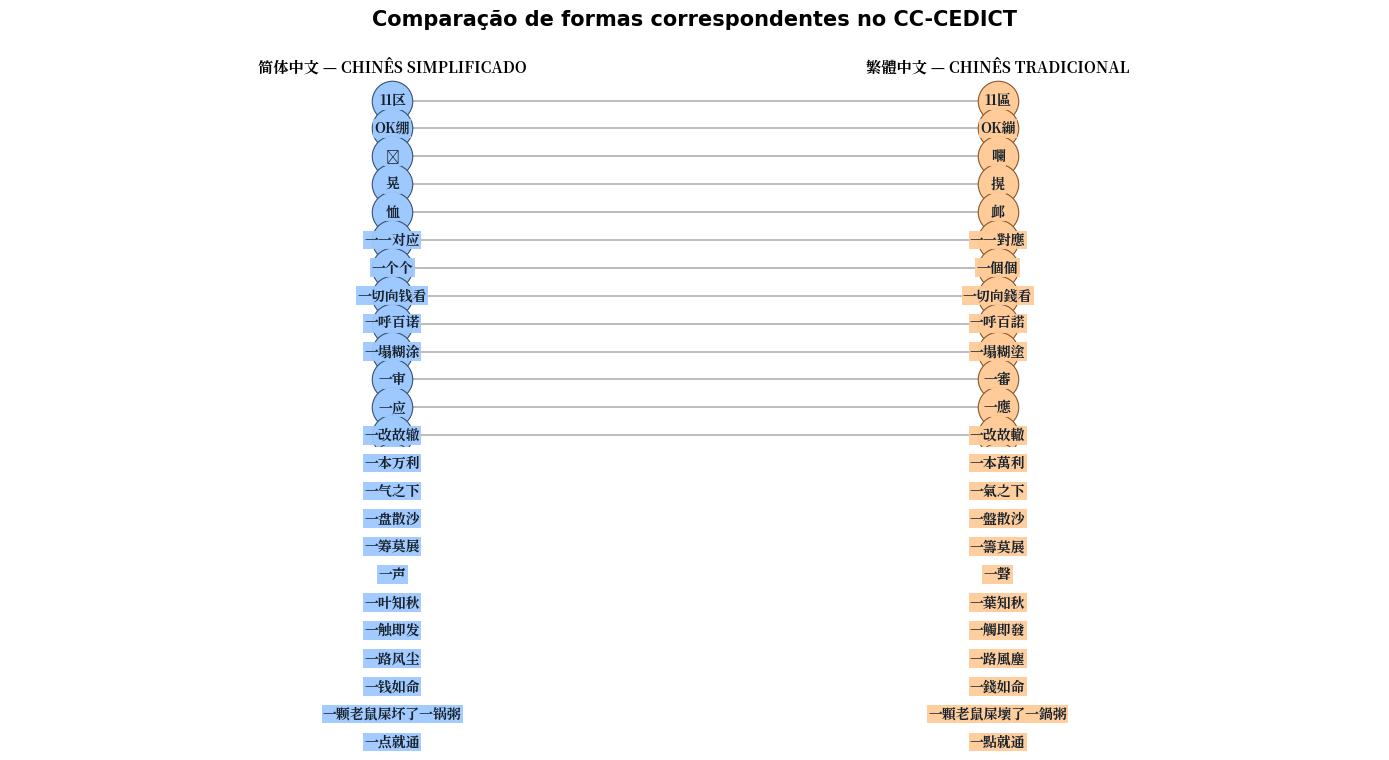

Chinês simplificado × tradicional: 24 pares distintos exibidos (cada linha conecta duas formas da mesma entrada do CC-CEDICT).


In [ ]:
# Visualizações comparativas com idiomas identificados, cores e layout em colunas.
# A seleção usa os caracteres com maior presença nos DOIS idiomas, em vez dos primeiros
# caracteres em ordem Unicode. A rede completa continua disponível nas variáveis G_*.

COMPARE_CHARS = 18          # quantidade de caracteres compartilhados exibidos
WORDS_PER_CHAR_COMPARE = 3  # quantidade máxima de palavras por caractere e idioma
PAIRS_TO_SHOW = 24          # pares distintos na comparação simplificado/tradicional

COLOR_LEFT = "#9EC9FF"      # palavras do idioma/variante à esquerda
COLOR_CHAR = "#B8E0D2"      # caracteres compartilhados
COLOR_RIGHT = "#FFCC99"     # palavras do idioma/variante à direita
EDGE_LEFT = "#6495C8"
EDGE_RIGHT = "#D18A4B"


def _word_neighbors(graph, char_node, prefixes):
    """Vizinhos de um caractere que são palavras de um ou mais idiomas."""
    return [n for n in graph.neighbors(char_node) if n.startswith(prefixes)]


def _display_node_label(node, prefixes):
    if node.startswith("CHAR:"):
        return node[len("CHAR:"):]
    for prefix in prefixes:
        if node.startswith(prefix):
            return node[len(prefix):]
    return node


def plot_language_comparison(graph, title, left_name, left_prefixes,
                             right_name, right_prefixes,
                             max_chars=COMPARE_CHARS,
                             words_per_char=WORDS_PER_CHAR_COMPARE):
    """Grafo em três colunas: palavras à esquerda, caracteres no centro, palavras à direita."""
    left_prefixes = tuple(left_prefixes)
    right_prefixes = tuple(right_prefixes)

    ranked_chars = []
    for node, data in graph.nodes(data=True):
        if data.get("bipartite") != "character":
            continue
        left_words = _word_neighbors(graph, node, left_prefixes)
        right_words = _word_neighbors(graph, node, right_prefixes)
        # Só comparar caracteres que realmente aparecem nos dois lados.
        if left_words and right_words:
            ranked_chars.append((node, left_words, right_words))

    ranked_chars.sort(
        key=lambda item: (
            min(len(item[1]), len(item[2])),
            len(item[1]) + len(item[2]),
            item[0]
        ),
        reverse=True
    )
    chosen = ranked_chars[:max_chars]
    if not chosen:
        print(f"Não foram encontrados caracteres compartilhados para: {title}")
        return

    # Coordenadas previsíveis em colunas, para que cada cor e idioma fique evidente.
    spacing = 1.35
    center_y = (len(chosen) - 1) * spacing / 2
    pos = {}
    chosen_nodes = set()
    left_y_suggestions = {}
    right_y_suggestions = {}
    char_nodes = []

    for idx, (char_node, left_words, right_words) in enumerate(chosen):
        y = center_y - idx * spacing
        pos[char_node] = (0.0, y)
        chosen_nodes.add(char_node)
        char_nodes.append(char_node)

        # Seleciona palavras com mais ligações primeiro; isso tende a mostrar palavras
        # que ilustram melhor o uso dos caracteres e reduz a chance de grupos vazios.
        left_words = sorted(left_words, key=lambda n: (-graph.degree(n), graph.nodes[n].get("label", n)))[:words_per_char]
        right_words = sorted(right_words, key=lambda n: (-graph.degree(n), graph.nodes[n].get("label", n)))[:words_per_char]

        for words, suggestions in ((left_words, left_y_suggestions), (right_words, right_y_suggestions)):
            if len(words) == 1:
                offsets = [0.0]
            else:
                offsets = [((j / (len(words) - 1)) - 0.5) * 0.78 for j in range(len(words))]
            for word_node, offset in zip(words, offsets):
                chosen_nodes.add(word_node)
                suggestions.setdefault(word_node, []).append(y + offset)

    for node, ys in left_y_suggestions.items():
        pos[node] = (-3.7, sum(ys) / len(ys))
    for node, ys in right_y_suggestions.items():
        pos[node] = (3.7, sum(ys) / len(ys))

    sample = graph.subgraph(chosen_nodes).copy()
    left_nodes = [n for n in sample.nodes if n.startswith(left_prefixes)]
    right_nodes = [n for n in sample.nodes if n.startswith(right_prefixes)]
    center_nodes = [n for n in sample.nodes if n.startswith("CHAR:")]
    left_edges, right_edges = [], []
    for u, v in sample.edges():
        if u.startswith(left_prefixes) or v.startswith(left_prefixes):
            left_edges.append((u, v))
        elif u.startswith(right_prefixes) or v.startswith(right_prefixes):
            right_edges.append((u, v))

    fig_height = max(9.5, len(chosen) * 0.68)
    fig, ax = plt.subplots(figsize=(17, fig_height))
    nx.draw_networkx_edges(sample, pos, edgelist=left_edges, edge_color=EDGE_LEFT,
                           alpha=0.48, width=1.0, ax=ax)
    nx.draw_networkx_edges(sample, pos, edgelist=right_edges, edge_color=EDGE_RIGHT,
                           alpha=0.48, width=1.0, ax=ax)
    nx.draw_networkx_nodes(sample, pos, nodelist=left_nodes, node_color=COLOR_LEFT,
                           node_size=520, edgecolors="#35516E", linewidths=0.7, ax=ax)
    nx.draw_networkx_nodes(sample, pos, nodelist=center_nodes, node_color=COLOR_CHAR,
                           node_size=1050, edgecolors="#386B59", linewidths=1.2, ax=ax)
    nx.draw_networkx_nodes(sample, pos, nodelist=right_nodes, node_color=COLOR_RIGHT,
                           node_size=520, edgecolors="#88572B", linewidths=0.7, ax=ax)

    # Rótulos manuais para usar a fonte CJK também nos nós e manter a leitura nítida.
    for node, (x, y) in pos.items():
        label = _display_node_label(node, left_prefixes + right_prefixes)
        fontsize = 13 if node.startswith("CHAR:") else 8.5
        if node.startswith("CHAR:"):
            label_color = COLOR_CHAR
        elif node.startswith(left_prefixes):
            label_color = COLOR_LEFT
        else:
            label_color = COLOR_RIGHT
        ax.text(x, y, label, fontproperties=cjk_font, fontsize=fontsize,
                ha="center", va="center", color="#17212B",
                bbox=dict(facecolor=label_color, edgecolor="none", alpha=0.94, pad=1.0),
                zorder=5)

    top_y = center_y + 1.25
    ax.text(-3.7, top_y, left_name, ha="center", va="bottom", fontsize=12,
            fontweight="bold", wrap=True)
    ax.text(0, top_y, "CARACTERES COMPARTILHADOS", ha="center", va="bottom",
            fontsize=12, fontweight="bold")
    ax.text(3.7, top_y, right_name, ha="center", va="bottom", fontsize=12,
            fontweight="bold", wrap=True)

    from matplotlib.lines import Line2D
    legend_items = [
        Line2D([0], [0], marker="o", color="w", label=left_name,
               markerfacecolor=COLOR_LEFT, markeredgecolor="#35516E", markersize=10),
        Line2D([0], [0], marker="o", color="w", label="Caractere Han/Kanji",
               markerfacecolor=COLOR_CHAR, markeredgecolor="#386B59", markersize=10),
        Line2D([0], [0], marker="o", color="w", label=right_name,
               markerfacecolor=COLOR_RIGHT, markeredgecolor="#88572B", markersize=10),
    ]
    ax.legend(handles=legend_items, loc="lower center", bbox_to_anchor=(0.5, -0.035),
              ncol=3, frameon=False, fontsize=9)
    ax.set_title(title, fontsize=16, pad=22, fontweight="bold")
    ax.set_xlim(-5.7, 5.7)
    ax.set_ylim(-center_y - 1.3, top_y + 0.7)
    ax.axis("off")
    fig.tight_layout()
    plt.show()
    print(f"{title}: {len(chosen)} caracteres compartilhados; "
          f"{len(left_nodes)} palavras à esquerda; {len(right_nodes)} palavras à direita; "
          f"{sample.number_of_edges()} ligações na amostra visual.")


def plot_simplified_traditional_pairs(df, max_pairs=PAIRS_TO_SHOW):
    """Mostra pares reais do CC-CEDICT em duas colunas alinhadas por entrada do dicionário."""
    pairs = df[["simplified", "traditional"]].copy()
    pairs = pairs.dropna()
    pairs["simplified"] = pairs["simplified"].astype(str).str.strip()
    pairs["traditional"] = pairs["traditional"].astype(str).str.strip()
    pairs = pairs[(pairs["simplified"] != "") & (pairs["traditional"] != "")]
    pairs = pairs[pairs["simplified"] != pairs["traditional"]]
    pairs = pairs.drop_duplicates(subset=["simplified", "traditional"]).reset_index(drop=True)

    if pairs.empty:
        print("Nenhum par diferente entre chinês simplificado e tradicional foi encontrado.")
        return

    # Amostra distribuída pelo dicionário em vez de usar apenas as primeiras entradas.
    n = min(max_pairs, len(pairs))
    if n == 1:
        selected_indices = [0]
    else:
        selected_indices = [round(i * (len(pairs) - 1) / (n - 1)) for i in range(n)]
    pairs = pairs.iloc[selected_indices].reset_index(drop=True)

    pair_graph = nx.Graph()
    pos = {}
    labels = {}
    for i, row in pairs.iterrows():
        simp_node = f"SIMP_PAIR_{i}"
        trad_node = f"TRAD_PAIR_{i}"
        y = (len(pairs) - 1) / 2 - i
        pair_graph.add_node(simp_node, language="chinese_simplified")
        pair_graph.add_node(trad_node, language="chinese_traditional")
        pair_graph.add_edge(simp_node, trad_node, relation="same_dictionary_entry")
        pos[simp_node] = (-1.9, y)
        pos[trad_node] = (1.9, y)
        labels[simp_node] = row["simplified"]
        labels[trad_node] = row["traditional"]

    fig, ax = plt.subplots(figsize=(14, max(9, len(pairs) * 0.47)))
    nx.draw_networkx_edges(pair_graph, pos, edge_color="#8B8B8B", alpha=0.68,
                           width=1.2, ax=ax)
    simp_nodes = [n for n in pair_graph.nodes if n.startswith("SIMP_PAIR_")]
    trad_nodes = [n for n in pair_graph.nodes if n.startswith("TRAD_PAIR_")]
    nx.draw_networkx_nodes(pair_graph, pos, nodelist=simp_nodes, node_color=COLOR_LEFT,
                           node_size=850, edgecolors="#35516E", linewidths=0.8, ax=ax)
    nx.draw_networkx_nodes(pair_graph, pos, nodelist=trad_nodes, node_color=COLOR_RIGHT,
                           node_size=850, edgecolors="#88572B", linewidths=0.8, ax=ax)
    for node, (x, y) in pos.items():
        label_color = COLOR_LEFT if node.startswith("SIMP_PAIR_") else COLOR_RIGHT
        ax.text(x, y, labels[node], fontproperties=cjk_font, fontsize=10,
                ha="center", va="center", color="#17212B",
                bbox=dict(facecolor=label_color, edgecolor="none", alpha=0.95, pad=1.0),
                zorder=5)
    top_y = (len(pairs) - 1) / 2 + 0.9
    ax.text(-1.9, top_y, "简体中文 — CHINÊS SIMPLIFICADO", ha="center", va="bottom",
            fontsize=11, fontweight="bold", fontproperties=cjk_font)
    ax.text(1.9, top_y, "繁體中文 — CHINÊS TRADICIONAL", ha="center", va="bottom",
            fontsize=11, fontweight="bold", fontproperties=cjk_font)
    ax.set_title("Comparação de formas correspondentes no CC-CEDICT", fontsize=15,
                 pad=20, fontweight="bold")
    ax.set_xlim(-4.3, 4.3)
    ax.set_ylim(-0.9, top_y + 0.8)
    ax.axis("off")
    fig.tight_layout()
    plt.show()
    print(f"Chinês simplificado × tradicional: {len(pairs)} pares distintos exibidos "
          f"(cada linha conecta duas formas da mesma entrada do CC-CEDICT).")


# Contagens antes dos desenhos: ajudam a distinguir volume de dados e limite visual.
def _chars_with_prefix(graph, prefixes):
    prefixes = tuple(prefixes)
    return {
        char_node
        for char_node, data in graph.nodes(data=True)
        if data.get("bipartite") == "character"
        and any(neighbor.startswith(prefixes) for neighbor in graph.neighbors(char_node))
    }

print("Resumo das redes completas carregadas:")
print(f"  Caracteres no japonês: {len(_chars_with_prefix(G_jp, ('JP_WORD:',)))}")
print(f"  Caracteres no chinês tradicional: {len(_chars_with_prefix(G_cn_trad, ('CN_TRAD_WORD:',)))}")
print(f"  Caracteres no chinês simplificado: {len(_chars_with_prefix(G_cn_simp, ('CN_WORD:',)))}")
print(f"  Compartilhados japonês/tradicional: {len(_chars_with_prefix(G_jp, ('JP_WORD:',)) & _chars_with_prefix(G_cn_trad, ('CN_TRAD_WORD:',)))}")
print(f"  Compartilhados japonês/simplificado: {len(_chars_with_prefix(G_jp, ('JP_WORD:',)) & _chars_with_prefix(G_cn_simp, ('CN_WORD:',)))}")

plot_language_comparison(
    G_jp_vs_trad,
    "Japonês × Chinês tradicional",
    "JAPONÊS (JMdict)", ["JP_WORD:"],
    "CHINÊS TRADICIONAL (CC-CEDICT)", ["CN_TRAD_WORD:"]
)

plot_language_comparison(
    G_jp_vs_simp,
    "Japonês × Chinês simplificado",
    "JAPONÊS (JMdict)", ["JP_WORD:"],
    "CHINÊS SIMPLIFICADO (CC-CEDICT)", ["CN_WORD:"]
)

plot_simplified_traditional_pairs(df_cn_mock)


## Grafos interativos com layout espalhado

Além dos gráficos organizados em colunas, esta seção gera redes interativas em que os nós se distribuem por um layout de forças. Os caracteres funcionam como pontos de ligação entre palavras; palavras que compartilham mais caracteres tendem a ficar próximas na rede.

**Como explorar:** arraste nós para reorganizar a rede, use a roda do mouse para aproximar/afastar, passe o mouse sobre um nó para ver idioma/definição/conexões e clique em um nó para destacar suas relações. A cor identifica o idioma/variante; as arestas mostram as relações. Na comparação simplificado × tradicional, a aresta roxa une formas da mesma entrada do CC-CEDICT.

Para manter o navegador responsivo, o desenho usa uma **amostra do grafo**, não todos os nós de uma vez. Ajuste `INTERACTIVE_MAX_CHARS` e `INTERACTIVE_WORDS_PER_CHAR` no código abaixo. As redes completas permanecem nas variáveis `G_jp_vs_trad`, `G_jp_vs_simp` e `G_cn_simp_vs_trad`.


In [ ]:
# Grafos interativos espalhados com PyVis.
# Arrastar = reposicionar nó | roda do mouse = zoom | passar o mouse = detalhes | clicar = destacar conexões.

from pyvis.network import Network
from IPython.display import display, HTML
import html as _html
import math as _math

# Ajustes de legibilidade/desempenho. Aumente gradualmente se o navegador suportar.
INTERACTIVE_MAX_CHARS = 50
INTERACTIVE_WORDS_PER_CHAR = 5
INTERACTIVE_HEIGHT = "760px"

# Paleta estável: a mesma variante mantém a mesma cor nos três grafos.
INTERACTIVE_COLORS = {
    "japanese": "#60A5FA",             # azul
    "chinese_traditional": "#FDBA74",  # laranja
    "chinese_simplified": "#86EFAC",   # verde
    "shared": "#DDD6FE",               # lilás: caractere Han/Kanji
}
INTERACTIVE_BORDERS = {
    "japanese": "#1D4ED8",
    "chinese_traditional": "#9A3412",
    "chinese_simplified": "#166534",
    "shared": "#7C3AED",
}
INTERACTIVE_LANGUAGE_NAMES = {
    "japanese": "Japonês (JMdict)",
    "chinese_traditional": "Chinês tradicional (CC-CEDICT)",
    "chinese_simplified": "Chinês simplificado (CC-CEDICT)",
    "shared": "Caractere Han/Kanji",
}


def _interactive_label(node, data):
    """Nome que aparece junto do nó na visualização."""
    label = data.get("label")
    if label is not None and str(label).strip():
        return str(label).strip()
    for prefix in ("JP_WORD:", "CN_TRAD_WORD:", "CN_WORD:", "CN_SIMP_PAIR:"):
        if node.startswith(prefix):
            return node[len(prefix):]
    if node.startswith("CHAR:"):
        return node[len("CHAR:"):]
    return str(node)


def _interactive_ranked_chars(graph, left_prefixes, right_prefixes):
    """Seleciona caracteres conectados a palavras dos dois lados da comparação."""
    left_prefixes = tuple(left_prefixes)
    right_prefixes = tuple(right_prefixes)
    ranked = []
    for char_node, attrs in graph.nodes(data=True):
        if attrs.get("bipartite") != "character" or not str(char_node).startswith("CHAR:"):
            continue
        left_words = [n for n in graph.neighbors(char_node) if n.startswith(left_prefixes)]
        right_words = [n for n in graph.neighbors(char_node) if n.startswith(right_prefixes)]
        if left_words and right_words:
            ranked.append((char_node, left_words, right_words))
    ranked.sort(
        key=lambda item: (min(len(item[1]), len(item[2])), len(item[1]) + len(item[2]), item[0]),
        reverse=True,
    )
    return ranked


def _interactive_sample(graph, left_prefixes, right_prefixes,
                        max_chars=INTERACTIVE_MAX_CHARS,
                        words_per_char=INTERACTIVE_WORDS_PER_CHAR):
    """Constrói uma amostra conectada, preservando palavras multi-caractere e pares de formas."""
    ranked = _interactive_ranked_chars(graph, left_prefixes, right_prefixes)
    if not ranked:
        return graph.subgraph([]).copy(), []

    chosen_chars = ranked[:max_chars]
    chosen_nodes = set()
    for char_node, left_words, right_words in chosen_chars:
        chosen_nodes.add(char_node)
        for words, prefixes in ((left_words, tuple(left_prefixes)), (right_words, tuple(right_prefixes))):
            # Prioriza palavras com mais ligações a caracteres, para revelar interseções entre palavras.
            words = sorted(
                words,
                key=lambda node: (-graph.degree(node), _interactive_label(node, graph.nodes[node]))
            )[:words_per_char]
            chosen_nodes.update(words)

    # Na comparação simplificado/tradicional, inclui a forma correspondente ligada pela mesma entrada.
    # Isso deixa explícito quando dois nós são variantes da mesma entrada do dicionário.
    for node in list(chosen_nodes):
        if node not in graph:
            continue
        for neighbor in graph.neighbors(node):
            relation = graph.edges[node, neighbor].get("relation", "")
            if relation == "traditional_simplified_entry_pair":
                chosen_nodes.add(neighbor)

    sample = graph.subgraph(chosen_nodes).copy()
    return sample, chosen_chars


def _safe_text(value):
    if value is None or pd.isna(value):
        return ""
    return str(value).strip()


def _interactive_detail_maps(sample):
    """Busca definições somente das palavras mostradas no subgrafo, evitando varrer tudo por nó."""
    wanted_jp, wanted_simp, wanted_trad = set(), set(), set()
    for node, attrs in sample.nodes(data=True):
        label = _interactive_label(node, attrs)
        if node.startswith("JP_WORD:"):
            wanted_jp.add(label)
        elif node.startswith(("CN_WORD:", "CN_SIMP_PAIR:")):
            wanted_simp.add(label)
        elif node.startswith("CN_TRAD_WORD:"):
            wanted_trad.add(label)

    details = {"japanese": {}, "chinese_simplified": {}, "chinese_traditional": {}}

    def add_detail(language, word, text):
        if not word or not text:
            return
        entries = details[language].setdefault(word, [])
        if text not in entries and len(entries) < 2:
            entries.append(text)

    if wanted_jp and {"word", "reading", "definition"}.issubset(df_jp_mock.columns):
        subset = df_jp_mock[df_jp_mock["word"].isin(wanted_jp)]
        for word, reading, definition in subset[["word", "reading", "definition"]].itertuples(index=False, name=None):
            word, reading, definition = _safe_text(word), _safe_text(reading), _safe_text(definition)
            info = (f"Leitura: {reading}. " if reading else "") + (f"Significado: {definition}" if definition else "")
            add_detail("japanese", word, info)

    needed_cn = (wanted_simp or wanted_trad) and {"simplified", "traditional", "pinyin", "definition"}.issubset(df_cn_mock.columns)
    if needed_cn:
        mask = df_cn_mock["simplified"].isin(wanted_simp) | df_cn_mock["traditional"].isin(wanted_trad)
        subset = df_cn_mock.loc[mask, ["simplified", "traditional", "pinyin", "definition"]]
        for simplified, traditional, pinyin, definition in subset.itertuples(index=False, name=None):
            simplified, traditional = _safe_text(simplified), _safe_text(traditional)
            pinyin, definition = _safe_text(pinyin), _safe_text(definition)
            info = (f"Pinyin: {pinyin}. " if pinyin else "") + (f"Significado: {definition}" if definition else "")
            add_detail("chinese_simplified", simplified, info)
            add_detail("chinese_traditional", traditional, info)

    return details


def _interactive_node_title(node, attrs, full_graph, left_prefixes, right_prefixes, detail_maps):
    label = _interactive_label(node, attrs)
    language = attrs.get("language", "shared")
    language_name = INTERACTIVE_LANGUAGE_NAMES.get(language, str(language))
    chunks = [f"<b>{_html.escape(language_name)}</b>", f"Forma: {_html.escape(label)}"]

    if attrs.get("bipartite") == "character":
        left_count = sum(n.startswith(tuple(left_prefixes)) for n in full_graph.neighbors(node))
        right_count = sum(n.startswith(tuple(right_prefixes)) for n in full_graph.neighbors(node))
        chunks.append(f"Palavras ligadas no lado esquerdo: {left_count}")
        chunks.append(f"Palavras ligadas no lado direito: {right_count}")
    else:
        detail_key = language if language in detail_maps else None
        if detail_key:
            for detail in detail_maps[detail_key].get(label, []):
                if detail:
                    chunks.append(_html.escape(detail))
        chunks.append(f"Caracteres ligados: {full_graph.degree(node)}")
    return "<br>".join(chunks)


def _display_force_graph(graph, title, left_name, left_prefixes,
                         right_name, right_prefixes):
    left_prefixes = tuple(left_prefixes)
    right_prefixes = tuple(right_prefixes)
    sample, ranked_chars = _interactive_sample(
        graph, left_prefixes, right_prefixes,
        max_chars=INTERACTIVE_MAX_CHARS,
        words_per_char=INTERACTIVE_WORDS_PER_CHAR,
    )
    if sample.number_of_nodes() == 0:
        print(f"{title}: não foram encontrados caracteres conectando os dois lados com os dados atuais.")
        return

    net = Network(
        height=INTERACTIVE_HEIGHT,
        width="100%",
        directed=False,
        notebook=True,
        cdn_resources="in_line",
        bgcolor="#FFFFFF",
        font_color="#1F2937",
    )
    detail_maps = _interactive_detail_maps(sample)

    for node, attrs in sample.nodes(data=True):
        label = _interactive_label(node, attrs)
        language = attrs.get("language", "shared")
        color = INTERACTIVE_COLORS.get(language, "#D1D5DB")
        border = INTERACTIVE_BORDERS.get(language, "#6B7280")
        is_character = attrs.get("bipartite") == "character"
        full_degree = graph.degree(node) if node in graph else sample.degree(node)
        size = (18 + min(13, int(_math.log1p(full_degree) * 2.2))) if is_character else (12 + min(5, sample.degree(node)))
        font_size = 18 if is_character else 12
        net.add_node(
            str(node),
            label=label,
            title=_interactive_node_title(
                node, attrs, graph, left_prefixes, right_prefixes, detail_maps
            ),
            color={"background": color, "border": border, "highlight": {"background": "#FDE68A", "border": "#111827"}},
            borderWidth=1.6,
            size=size,
            shape="diamond" if is_character else "dot",
            font={"size": font_size, "face": "Arial, sans-serif", "strokeWidth": 2, "strokeColor": "#FFFFFF"},
            margin=7,
            shadow={"enabled": True, "size": 4, "x": 1, "y": 1},
        )

    for u, v, edge_attrs in sample.edges(data=True):
        relation = edge_attrs.get("relation", "contains_character")
        if relation == "traditional_simplified_entry_pair":
            edge_color = "#9333EA"
            edge_title = "Duas formas correspondentes na mesma entrada do CC-CEDICT"
            width = 2.8
            dashes = False
        else:
            word_node = u if sample.nodes[u].get("bipartite") == "word" else v
            word_language = sample.nodes[word_node].get("language", "shared")
            edge_color = INTERACTIVE_COLORS.get(word_language, "#9CA3AF")
            char_node = v if word_node == u else u
            edge_title = f"{_html.escape(_interactive_label(word_node, sample.nodes[word_node]))} contém o caractere {_html.escape(_interactive_label(char_node, sample.nodes[char_node]))}"
            width = 1.5
            dashes = False
        net.add_edge(
            str(u), str(v), color=edge_color, title=edge_title,
            width=width, dashes=dashes,
        )

    net.set_options(r"""var options = {
      "nodes": {"scaling": {"min": 10, "max": 32}, "font": {"size": 12}, "labelHighlightBold": true},
      "edges": {"smooth": {"enabled": true, "type": "dynamic"}, "selectionWidth": 2.5, "hoverWidth": 1.5},
      "layout": {"randomSeed": 42, "improvedLayout": true},
      "interaction": {"hover": true, "tooltipDelay": 120, "navigationButtons": true,
                      "keyboard": {"enabled": true, "bindToWindow": false},
                      "dragNodes": true, "dragView": true, "zoomView": true,
                      "selectConnectedEdges": true, "hideEdgesOnDrag": false},
      "physics": {"enabled": true, "solver": "barnesHut",
                   "barnesHut": {"gravitationalConstant": -18000, "centralGravity": 0.18,
                                 "springLength": 105, "springConstant": 0.035,
                                 "damping": 0.38, "avoidOverlap": 0.8},
                   "stabilization": {"enabled": true, "iterations": 650, "updateInterval": 30}}
    }""")

    # Legenda específica deste grafo: deixa claro quais idiomas estão realmente presentes.
    def _prefix_language(prefixes):
        prefixes = tuple(prefixes)
        if any(p.startswith("JP_WORD") for p in prefixes):
            return "japanese"
        if any(p.startswith(("CN_SIMP_PAIR", "CN_WORD")) for p in prefixes):
            return "chinese_simplified"
        if any(p.startswith("CN_TRAD_WORD") for p in prefixes):
            return "chinese_traditional"
        return "shared"

    left_language = _prefix_language(left_prefixes)
    right_language = _prefix_language(right_prefixes)
    palette_html = (
        f'<span style="color:{INTERACTIVE_COLORS[left_language]};font-weight:700">● {_html.escape(left_name)}</span> &nbsp; '
        f'<span style="color:{INTERACTIVE_COLORS["shared"]};font-weight:700">◆ Caractere Han/Kanji</span> &nbsp; '
        f'<span style="color:{INTERACTIVE_COLORS[right_language]};font-weight:700">● {_html.escape(right_name)}</span>'
    )
    has_pair_edges = any(data.get("relation") == "traditional_simplified_entry_pair" for _, _, data in sample.edges(data=True))
    if has_pair_edges:
        palette_html += ' &nbsp; <span style="color:#9333EA;font-weight:700">━ Formas da mesma entrada do CC-CEDICT</span>'
    display(HTML(
        f'<div style="font-family:Arial,sans-serif;margin:10px 0 6px 0">'
        f'<h3 style="margin:4px 0">{_html.escape(title)}</h3>'
        f'<div style="font-size:13px;line-height:1.8">{palette_html}</div>'
        f'<div style="font-size:12px;color:#4B5563">Arraste os nós, use o zoom e passe o mouse para ver detalhes. '
        f'Amostra atual: {sample.number_of_nodes()} nós e {sample.number_of_edges()} arestas.</div></div>'
    ))

    # Iframe srcdoc isole o JavaScript de cada rede, para que as três visualizações funcionem juntas.
    html_doc = net.generate_html(notebook=True)
    escaped_doc = _html.escape(html_doc, quote=True)
    iframe = (
        f'<iframe title="{_html.escape(title, quote=True)}" '
        f'width="100%" height="{INTERACTIVE_HEIGHT}" '
        'style="border:1px solid #D1D5DB;border-radius:8px;background:#FFFFFF" '
        'sandbox="allow-scripts" '
        f'srcdoc="{escaped_doc}"></iframe>'
    )
    display(HTML(iframe))
    chars_shown = sum(1 for n, data in sample.nodes(data=True) if data.get("bipartite") == "character")
    print(f"{title}: {chars_shown} nós de caracteres; {sample.number_of_nodes()} nós totais; {sample.number_of_edges()} arestas.")


# 1. Japonês × chinês tradicional
_display_force_graph(
    G_jp_vs_trad,
    "Grafo interativo — japonês × chinês tradicional",
    "JAPONÊS", ["JP_WORD:"],
    "CHINÊS TRADICIONAL", ["CN_TRAD_WORD:"],
)

# 2. Japonês × chinês simplificado
_display_force_graph(
    G_jp_vs_simp,
    "Grafo interativo — japonês × chinês simplificado",
    "JAPONÊS", ["JP_WORD:"],
    "CHINÊS SIMPLIFICADO", ["CN_WORD:"],
)

# 3. Chinês simplificado × tradicional: inclui a ligação direta entre formas da mesma entrada.
_display_force_graph(
    G_cn_simp_vs_trad,
    "Grafo interativo — chinês simplificado × chinês tradicional",
    "CHINÊS SIMPLIFICADO", ["CN_SIMP_PAIR:"],
    "CHINÊS TRADICIONAL", ["CN_TRAD_WORD:"],
)


/usr/local/lib/python3.13/dist-packages/IPython/core/display.py:724: UserWarning: Consider using IPython.display.IFrame instead
  warnings.warn("Consider using IPython.display.IFrame instead")


Grafo interativo — japonês × chinês tradicional: 50 nós de caracteres; 413 nós totais; 428 arestas.


/usr/local/lib/python3.13/dist-packages/IPython/core/display.py:724: UserWarning: Consider using IPython.display.IFrame instead
  warnings.warn("Consider using IPython.display.IFrame instead")


Grafo interativo — japonês × chinês simplificado: 50 nós de caracteres; 393 nós totais; 404 arestas.


/usr/local/lib/python3.13/dist-packages/IPython/core/display.py:724: UserWarning: Consider using IPython.display.IFrame instead
  warnings.warn("Consider using IPython.display.IFrame instead")


Grafo interativo — chinês simplificado × chinês tradicional: 50 nós de caracteres; 456 nós totais; 1195 arestas.
